In [12]:
import sys, os
sys.path.append(os.path.abspath(os.path.join("..")))

In [13]:
import numpy as np
import sklearn
from sklearn.model_selection import train_test_split
from src.features import clean_and_preprocess_data
from src.models import MultipleLinearRegression
from src.models import evaluate_variant
from src.diagnostics import average_residual_spread_by_hour
from src.features import split_sets_tr_val
from src.models import SGDLinearRegression

let us now keep our dataset as it is and then fit a model on it ! 
Keeping Registered and Casual t verify model's multicollinearity and why redundant feature affect our model! 

In [14]:
import pandas as pd

df = pd.read_csv("../data/hour.csv")

In [15]:
df = df.drop(columns=['instant', 'dteday'])
print(df.columns)
X = df.iloc[:, :14]
print(X.columns)
y = df.iloc[:, -1]
y

Index(['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual',
       'registered', 'cnt'],
      dtype='object')
Index(['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual',
       'registered'],
      dtype='object')


0         16
1         40
2         32
3         13
4          1
        ... 
17374    119
17375     89
17376     90
17377     61
17378     49
Name: cnt, Length: 17379, dtype: int64

I had to predict the cnt but i just included `registered` and `casual` those are the things i have to predict and i just kept it in my training model sorry!! 

In [16]:
X_train_full, y_train_full, X_test_full, y_test_full = train_test_split(X, y, test_size=0.2, shuffle=False)

## for X_val[hr] for residual plot

_, _,X_val, _ = split_sets_tr_val(X_train_full,y_train_full, feature_cols=X.columns)

hr_val_original = X_val['hr'].copy()

X = X.drop(columns=['temp'])
X_tr, y_tr_log, X_val, y_val_log = clean_and_preprocess_data(df, target_cols='cnt', feature_cols=X.columns)

In [17]:
metrics, summary, y_pred, y_val_true = evaluate_variant(X_tr, y_tr_log, X_val, y_val_log)

In [18]:
from IPython.display import display

display(metrics)
display(summary)

,MSE,MAE,RMSE,Val R2,Train R2,Adjusted_R2_Val,SSE,SST,SSM
0,0.351406,0.448511,0.592795,0.812205,0.889893,0.809602,977.259515,5203.849792,7655.5835


,Beta Hat,Standard Error,t_stats,p_values,CI lower,CI upper
Intercept,2.879097,0.034893,82.512697,0.000000e+00,2.810701,2.947493
yr,0.211642,0.013573,15.592916,0.000000e+00,0.185037,0.238248
mnth,0.005900,0.002651,2.225223,2.608633e-02,0.000703,0.011097
holiday,-0.082970,0.027822,-2.982159,2.868462e-03,-0.137506,-0.028434
weekday,0.015383,0.002212,6.954589,3.735012e-12,0.011047,0.019719
workingday,-0.147492,0.011571,-12.747202,0.000000e+00,-0.170173,-0.124812
atemp,0.773141,0.044379,17.421462,0.000000e+00,0.686151,0.860131
hum,-0.000808,0.029531,-0.027353,9.781787e-01,-0.058693,0.057078
windspeed,-0.090224,0.037663,-2.395545,1.661216e-02,-0.164051,-0.016397
casual,0.001857,0.000173,10.755023,0.000000e+00,0.001519,0.002195


(2781,)


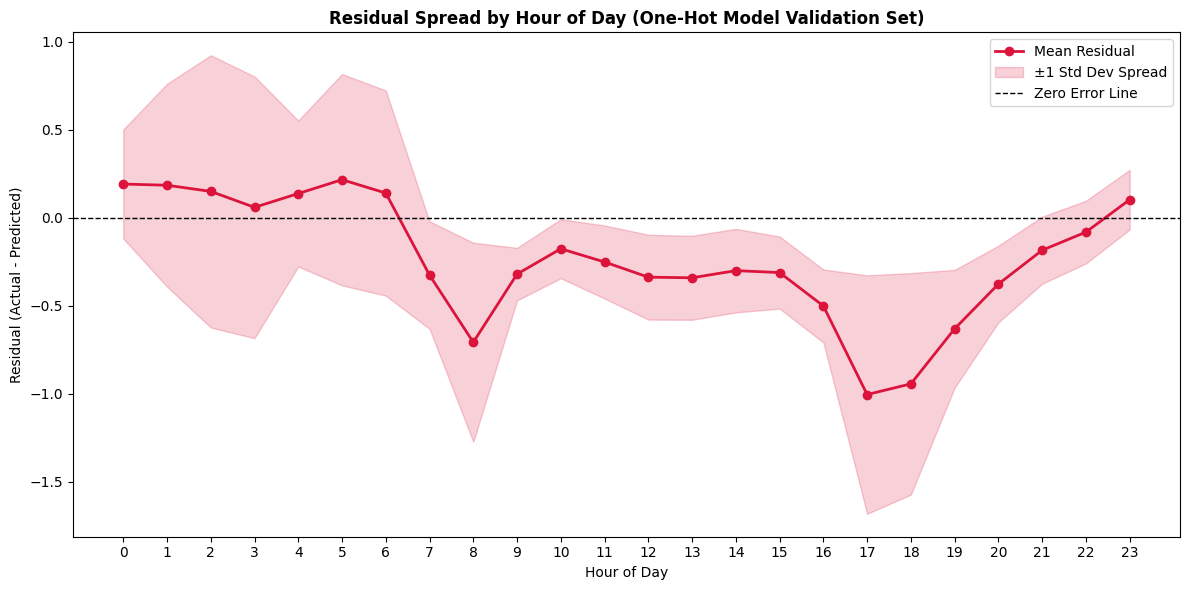

In [19]:


residual = y_val_true - y_pred
residual = np.ravel(residual)
print(residual.shape)
average_residual_spread_by_hour(hr_val_original, residual=residual)

using `registered` as y target

In [20]:
X.columns

Index(['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday',
       'weathersit', 'atemp', 'hum', 'windspeed', 'casual', 'registered'],
      dtype='object')

In [ ]:
sgd = SGDLinearRegression()
sgd.fit_sgd(X_tr,y_tr_log, epochs=2000, )
y_pred = sgd.predict(X_val)
r2_score = sgd.r2_score(X_val, y_val_log)


In [31]:
print(r2_score)

-26953.82823096973
